# OLCRouteMC - Test on the 22 x 22 Grid

Every computation behind Section 6.6.3 of the thesis. A run is skipped whenever its trace file already exists, so the notebook can be executed from top to bottom without repeating the
searches. Results are written to `OLCRouteMC_Test_22x22_Grid/data`, figures to `OLCRouteMC_Test_22x22_Grid/figures`.

In [1]:
# Check the environment.
import importlib.util
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

missing = [name for name in ("networkx", "matplotlib") if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError(f"missing packages: {', '.join(missing)}. See the README of the repository.")
if importlib.util.find_spec("LineCover") is None:
    raise ImportError("LineCover not found. Run this notebook from the notebooks folder of the repository.")

import json
import math
import statistics
import time

import matplotlib.pyplot as plt

from LineCover.SystemKit import figstyle
from LineCover.SystemKit.network import Network, get_grid_graph_data
from LineCover.SystemKit.buses_system import system_period
from LineCover.SystemKit.system_plot import (period_histogram, pair_period_histogram, pair_periods,
                                             load_heatmap, arc_load, route_figure)
from LineCover.Metaheuristics.olc_route_mc import (olc_route_mc, trace_writer, evaluate_trace,
                                                   system_of_routes)

figstyle.apply_style()

In [2]:
K = 22                          # 22x22 grid
BUS_COUNTS = [125, 250, 500]    # numbers of buses
M, EVAL_M = 20000, 20000        # search sample and evaluation sample
BUDGET, BLOCK = 500000, 25000   # evaluations in total and per block
L_MAX = 5                       # segment length of local search and perturbation
STAGNATION = 20                 # failed iterations before the perturbation strength is raised
DELTA = 0.05                    # error probability of the confidence intervals
DETAILED = 500                  # the run that also gets the periods histogram, the load and the pair periods

NAME = "OLCRouteMC_Test_22x22_Grid"
DATA, FIGURES = Path(NAME) / "data", Path(NAME) / "figures"
DATA.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

def stem(B):
    """File stem of the run with B buses."""
    return f"{K}x{K}_N{B}_M{M}"

def paths(B):
    """Trace, result and re-evaluation file of the run with B buses."""
    return (DATA / f"mc_trace_{stem(B)}.jsonl", DATA / f"mc_result_{stem(B)}.json",
            DATA / f"mc_eval_{stem(B)}.json")

edges, pos = get_grid_graph_data(K, K)
network = Network(edge_list=edges, pos=pos)
G = network.graph
print(f"{G.number_of_nodes()} nodes, {G.number_of_edges() // 2} edges, "
      f"{G.number_of_nodes() * (G.number_of_nodes() - 1)} node pairs")

484 nodes, 924 edges, 233772 node pairs


## Test Runs

A run whose trace file exists (from a previous run) is skipped, so this cell does nothing once the data is there.

In [3]:
for B in BUS_COUNTS:
    trace_path, result_path, _ = paths(B)
    if trace_path.exists():
        print(f"{B} buses: trace exists, skipped")
        continue

    print(f"{B} buses", flush=True)
    start = time.perf_counter()
    result = olc_route_mc(G, N=B, max_evaluations=BUDGET, M=M, eval_M=EVAL_M, block=BLOCK,
                          ls_L_max=L_MAX, pert_L_max=L_MAX, s=STAGNATION, delta=DELTA,
                          seed=0, sample_seed=0, phase_seed=0,
                          on_block=trace_writer(str(trace_path)))
    print(f"   {time.perf_counter() - start:.0f} s, search {result.search_improvement:.2%}, "
          f"evaluation {result.eval_improvement:.2%}, difference {result.eval_difference:.4f} "
          f"{[round(x, 4) for x in result.eval_difference_interval]}", flush=True)

    with open(result_path, "w") as file:
        json.dump({"K": K, "B": B, "M": result.M, "eval_M": result.eval_M, "budget": BUDGET,
                   "L_max": L_MAX, "s": STAGNATION, "delta": DELTA,
                   "search": [result.search_initial_estimate, result.search_final_estimate],
                   "eval": [result.eval_initial_estimate, result.eval_final_estimate],
                   "ci": [list(result.eval_initial_interval), list(result.eval_final_interval)],
                   "difference": [result.eval_difference,
                                  list(result.eval_difference_interval)]}, file, indent=1)

125 buses: trace exists, skipped
250 buses: trace exists, skipped
500 buses: trace exists, skipped


## Re-Evaluation of Every Block on the Evaluation Sample

Estimate the ensemble average on the evaluation sample after every block of 25 000 objective evaluations of the total 500 000. Everything below reads the stored files only, so the figures can be rebuilt without the runs.

In [4]:
runs = {}
for B in BUS_COUNTS:
    trace_path, result_path, eval_path = paths(B)
    with open(trace_path) as file:
        records = [json.loads(line) for line in file if line.strip()]

    if eval_path.exists():
        with open(eval_path) as file:
            trace = json.load(file)
    else:
        start = time.perf_counter()
        trace = evaluate_trace(G, str(trace_path), eval_M=EVAL_M, sample_seed=1)
        with open(eval_path, "w") as file:
            json.dump(trace, file, indent=1)
        print(f"{B} buses: {len(trace)} blocks re-evaluated in {time.perf_counter() - start:.0f} s")

    with open(result_path) as file:
        result = json.load(file)

    runs[B] = {"trace": trace, "result": result,
               "initial": system_of_routes(G, records[0]["routes"]),
               "final": system_of_routes(G, records[-1]["routes"])}

print(f"{len(runs)} runs loaded: {', '.join(str(B) for B in runs)} buses")

3 runs loaded: 125, 250, 500 buses


## The Numbers Quoted in the Thesis

In [5]:
def circuit_stats(bus):
    """Period, edges travelled in both directions, distinct edges, nodes and covered pairs."""
    arcs = set(bus.ArcList)
    twice = sum(1 for u, v in bus.ArcList if (v, u) in arcs) // 2
    edges = {(min(u, v), max(u, v)) for u, v in bus.ArcList}
    nodes = len(bus.NodeSet)

    return bus.P_b, twice, len(edges), nodes, nodes * (nodes - 1)

def edge_load(system):
    """Traversals per undirected edge, both directions summed."""
    load = {}
    for (u, v), count in arc_load(system).items():
        key = (min(u, v), max(u, v))
        load[key] = load.get(key, 0) + count

    return load

def examples_of(run):
    """The shortest, a median and the longest circuit of the final system, and the same buses before."""
    by_period = sorted(run["final"].buses.values(), key=lambda bus: bus.P_b)
    final = [by_period[0], by_period[len(by_period) // 2], by_period[-1]]

    return [run["initial"].buses[bus.id] for bus in final], final

pairs = G.number_of_nodes() * (G.number_of_nodes() - 1)
for B, run in runs.items():
    trace, result = run["trace"], run["result"]
    search, evaluation = result["search"], result["eval"]
    difference, interval = result["difference"]
    before = [bus.P_b for bus in run["initial"].buses.values()]
    after = [bus.P_b for bus in run["final"].buses.values()]

    print(f"=== {B} buses")
    print(f"   search sample:     {search[0]:.2f} -> {search[1]:.2f} "
          f"({(search[0] - search[1]) / search[0]:.2%})")
    print(f"   evaluation sample: {evaluation[0]:.2f} -> {evaluation[1]:.2f} "
          f"({(evaluation[0] - evaluation[1]) / evaluation[0]:.2%}), "
          f"final interval [{result['ci'][1][0]:.2f}, {result['ci'][1][1]:.2f}]")
    print(f"   difference: {difference:.2f} [{interval[0]:.2f}, {interval[1]:.2f}], "
          f"surviving share {(evaluation[0] - evaluation[1]) / evaluation[0] / ((search[0] - search[1]) / search[0]):.0%}")
    print(f"   gap at the start {trace[0]['search_estimate'] - trace[0]['eval_estimate']:+.2f}, "
          f"at the end {trace[-1]['search_estimate'] - trace[-1]['eval_estimate']:+.2f}")
    print(f"   P_b median {statistics.median(before)} -> {statistics.median(after)}, "
          f"mean {statistics.mean(before):.1f} -> {statistics.mean(after):.1f}, "
          f"total length {sum(before)} -> {sum(after)}")

    load_before, load_after = edge_load(run["initial"]), edge_load(run["final"])
    print(f"   edges carrying buses {len(load_before)} -> {len(load_after)} of {G.number_of_edges() // 2}, "
          f"mean load {statistics.mean(load_before.values()):.1f} -> {statistics.mean(load_after.values()):.1f}, "
          f"max {max(load_before.values())} -> {max(load_after.values())}")

    for bus_before, bus_after in zip(*examples_of(run)):
        b, a = circuit_stats(bus_before), circuit_stats(bus_after)
        print(f"   bus {bus_before.id}: P_b {b[0]} -> {a[0]}, edges travelled twice {b[1]} -> {a[1]}, "
              f"distinct edges {b[2]} -> {a[2]}, nodes {b[3]} -> {a[3]}, "
              f"covered pairs {b[4]} -> {a[4]} ({b[4] / pairs:.1%} -> {a[4] / pairs:.1%})")

=== 125 buses
   search sample:     105.27 -> 91.86 (12.74%)
   evaluation sample: 105.63 -> 97.52 (7.68%), final interval [96.37, 98.66]
   difference: -8.11 [-8.89, -7.33], surviving share 60%
   gap at the start -0.35, at the end -5.66
   P_b median 86 -> 84, mean 108.4 -> 106.4, total length 13548 -> 13304
   edges carrying buses 924 -> 924 of 924, mean load 14.7 -> 14.4, max 32 -> 30
   bus 102: P_b 68 -> 62, edges travelled twice 6 -> 2, distinct edges 62 -> 60, nodes 59 -> 58, covered pairs 3422 -> 3306 (1.5% -> 1.4%)
   bus 11: P_b 84 -> 84, edges travelled twice 12 -> 11, distinct edges 72 -> 73, nodes 69 -> 69, covered pairs 4692 -> 4692 (2.0% -> 2.0%)
   bus 19: P_b 342 -> 340, edges travelled twice 95 -> 72, distinct edges 247 -> 268, nodes 230 -> 243, covered pairs 52670 -> 58806 (22.5% -> 25.2%)
=== 250 buses
   search sample:     74.28 -> 63.98 (13.86%)
   evaluation sample: 74.20 -> 68.34 (7.91%), final interval [67.49, 69.18]
   difference: -5.87 [-6.49, -5.24], surviv

## System Period $T$ and Pair Periods $T_{uv}$

lcm(1, ..., m) of the graph has 799 digits
 125 buses, initial: system period T has 41 digits
 125 buses,   final: system period T has 36 digits
 250 buses, initial: system period T has 34 digits
 250 buses,   final: system period T has 36 digits
 500 buses, initial: system period T has 26 digits
 500 buses,   final: system period T has 24 digits

500 buses, final system: T_uv over 2000 random pairs, median 7 digits, largest 20 digits


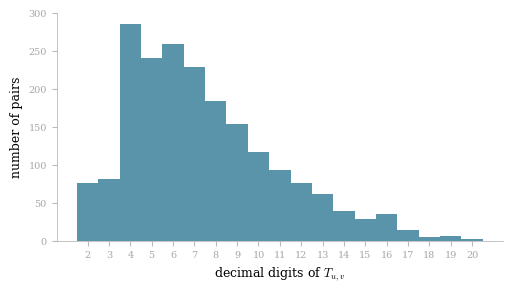

In [6]:
print(f"lcm(1, ..., m) of the graph has {len(str(system_period(G)))} digits")
for B, run in runs.items():
    for name in ("initial", "final"):
        T = math.lcm(*[bus.P_b for bus in run[name].buses.values()])
        print(f"{B:>4} buses, {name:>7}: system period T has {len(str(T))} digits")

values = pair_periods(runs[DETAILED]["final"])
print(f"\n{DETAILED} buses, final system: T_uv over {len(values)} random pairs, "
      f"median {statistics.median(len(str(value)) for value in values):.0f} digits, "
      f"largest {len(str(max(values)))} digits")
pair_period_histogram(runs[DETAILED]["final"], filename=f"{FIGURES}/pair_periods_N{DETAILED}.pdf");

## Convergence on the Search and on the Evaluation Sample

125 buses
         0  search 105.2730  evaluation 105.6272  [104.3930, 106.8614]
     25000  search  98.5830  evaluation 101.8853  [100.6934, 103.0772]
     50000  search  96.6724  evaluation 100.6079  [99.4293, 101.7865]
     75000  search  96.2775  evaluation 100.3124  [99.1374, 101.4874]
    100000  search  95.3823  evaluation  99.5993  [98.4298, 100.7688]
    125000  search  94.9963  evaluation  99.3344  [98.1678, 100.5010]
    150000  search  94.6558  evaluation  99.0328  [97.8715, 100.1941]
    175000  search  94.4312  evaluation  98.9720  [97.8104, 100.1337]
    200000  search  94.1473  evaluation  98.8111  [97.6510, 99.9711]
    225000  search  93.9513  evaluation  98.6513  [97.4950, 99.8076]
    250000  search  93.7397  evaluation  98.5509  [97.3963, 99.7056]
    275000  search  93.4046  evaluation  98.3702  [97.2171, 99.5233]
    300000  search  93.1881  evaluation  98.2573  [97.1042, 99.4105]
    325000  search  93.0791  evaluation  98.1986  [97.0461, 99.3512]
    350000  se

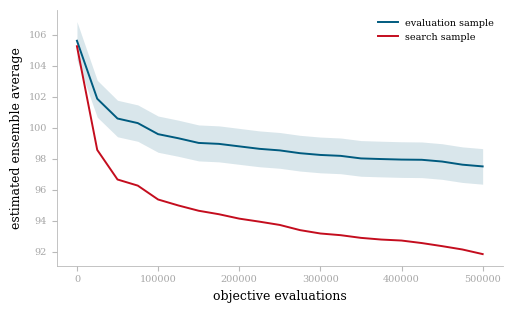

250 buses
         0  search  74.2783  evaluation  74.2021  [73.2711, 75.1331]
     25000  search  70.0913  evaluation  71.8740  [70.9753, 72.7727]
     50000  search  68.0304  evaluation  70.7219  [69.8396, 71.6042]
     75000  search  67.1352  evaluation  70.1410  [69.2669, 71.0151]
    100000  search  66.8832  evaluation  69.9835  [69.1112, 70.8559]
    125000  search  66.4610  evaluation  69.7161  [68.8477, 70.5845]
    150000  search  66.1809  evaluation  69.5111  [68.6453, 70.3770]
    175000  search  65.6546  evaluation  69.1635  [68.2999, 70.0272]
    200000  search  65.5023  evaluation  69.0731  [68.2103, 69.9358]
    225000  search  65.3011  evaluation  69.0023  [68.1413, 69.8634]
    250000  search  65.0985  evaluation  68.9725  [68.1117, 69.8334]
    275000  search  64.9277  evaluation  68.8605  [68.0025, 69.7184]
    300000  search  64.7765  evaluation  68.7745  [67.9180, 69.6309]
    325000  search  64.6908  evaluation  68.7608  [67.9040, 69.6175]
    350000  search  64.5

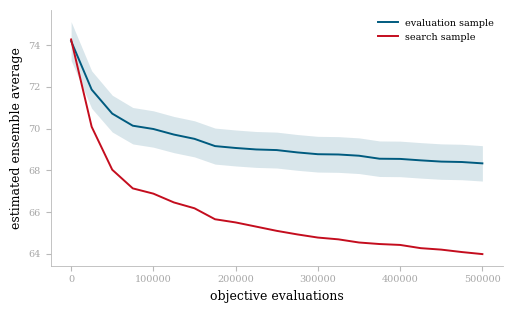

500 buses
         0  search  43.0613  evaluation  42.7469  [42.3607, 43.1331]
     25000  search  41.4300  evaluation  42.1931  [41.8148, 42.5714]
     50000  search  40.4480  evaluation  41.9576  [41.5824, 42.3329]
     75000  search  40.1496  evaluation  41.7860  [41.4126, 42.1593]
    100000  search  39.8168  evaluation  41.6488  [41.2796, 42.0180]
    125000  search  39.3842  evaluation  41.4722  [41.1048, 41.8396]
    150000  search  39.2063  evaluation  41.4201  [41.0524, 41.7877]
    175000  search  39.0898  evaluation  41.3930  [41.0257, 41.7604]
    200000  search  39.0358  evaluation  41.3962  [41.0289, 41.7635]
    225000  search  38.9372  evaluation  41.3413  [40.9753, 41.7073]
    250000  search  38.8346  evaluation  41.3171  [40.9514, 41.6829]
    275000  search  38.6301  evaluation  41.2708  [40.9055, 41.6360]
    300000  search  38.5680  evaluation  41.2287  [40.8637, 41.5936]
    325000  search  38.4226  evaluation  41.1345  [40.7713, 41.4977]
    350000  search  38.2

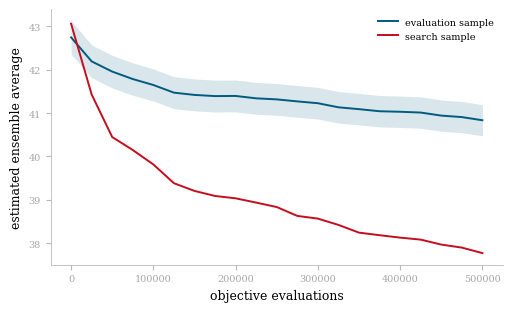

In [7]:
def plain_axes(ax):
    """Axis style of the thesis figures."""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(figstyle.AXIS_GREY)
        ax.spines[side].set_linewidth(figstyle.LW_AXIS)
    ax.tick_params(labelsize=figstyle.FS_SCRIPT, color=figstyle.AXIS_GREY,
                   labelcolor=figstyle.LABEL_GREY)

def convergence_figure(trace, filename):
    """Estimate on the search sample against the estimate on the evaluation sample."""
    evaluations = [row["evaluations"] for row in trace]
    fig, ax = plt.subplots(figsize=(5.2, 3.2))
    ax.fill_between(evaluations, [row["eval_interval"][0] for row in trace],
                    [row["eval_interval"][1] for row in trace],
                    color=figstyle.TUBLUE, alpha=0.15, linewidth=0)
    ax.plot(evaluations, [row["eval_estimate"] for row in trace], color=figstyle.TUBLUE,
            linewidth=1.4, label="evaluation sample")
    ax.plot(evaluations, [row["search_estimate"] for row in trace], color=figstyle.TURED,
            linewidth=1.4, label="search sample")
    ax.set_xlabel("objective evaluations", fontsize=figstyle.FS_SMALL)
    ax.set_ylabel("estimated ensemble average", fontsize=figstyle.FS_SMALL)
    plain_axes(ax)
    ax.legend(fontsize=figstyle.FS_SCRIPT, frameon=False)
    fig.tight_layout()
    fig.savefig(filename)
    plt.show()

for B, run in runs.items():
    print(f"{B} buses")
    for row in run["trace"]:
        print(f"   {row['evaluations']:7d}  search {row['search_estimate']:8.4f}  "
              f"evaluation {row['eval_estimate']:8.4f}  "
              f"[{row['eval_interval'][0]:.4f}, {row['eval_interval'][1]:.4f}]")
    convergence_figure(run["trace"], f"{FIGURES}/convergence_N{B}.pdf")

## All Runs in One Figure

Every curve is divided by its own value at the start solution, so that the fleet sizes share one axis. Solid lines are the evaluation sample, dashed lines the search sample.

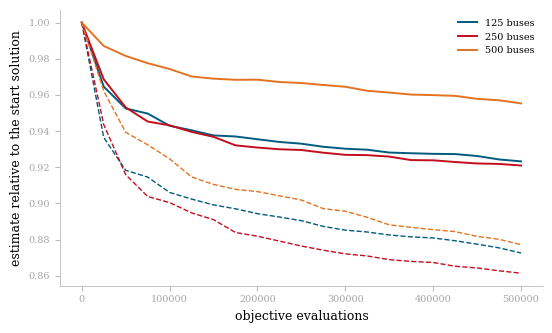

In [8]:
if len(runs) > 1:
    fig, ax = plt.subplots(figsize=(5.6, 3.4))
    for B, color in zip(runs, figstyle.BUS_COLORS):
        trace = runs[B]["trace"]
        evaluations = [row["evaluations"] for row in trace]
        ax.plot(evaluations, [row["eval_estimate"] / trace[0]["eval_estimate"] for row in trace],
                color=color, linewidth=1.4, label=f"{B} buses")
        ax.plot(evaluations, [row["search_estimate"] / trace[0]["search_estimate"] for row in trace],
                color=color, linewidth=1.0, linestyle="--")
    ax.set_xlabel("objective evaluations", fontsize=figstyle.FS_SMALL)
    ax.set_ylabel("estimate relative to the start solution", fontsize=figstyle.FS_SMALL)
    plain_axes(ax)
    ax.legend(fontsize=figstyle.FS_SCRIPT, frameon=False)
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/convergence_all.pdf")
    plt.show()

## Example Bus Routes

The shortest, a median and the longest circuit of the final system, and the same three buses in the initial solution.

125 buses: P_b [68, 84, 342] -> [62, 84, 340]


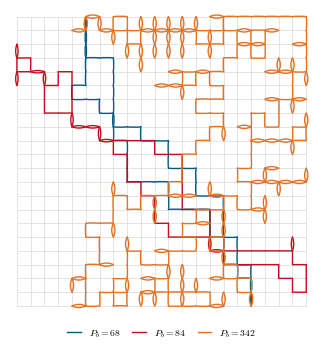

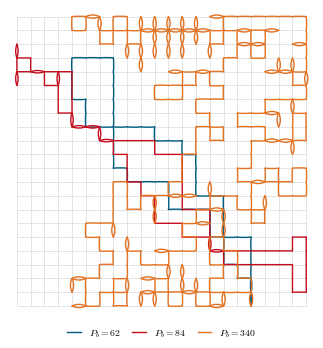

250 buses: P_b [60, 72, 278] -> [56, 72, 274]


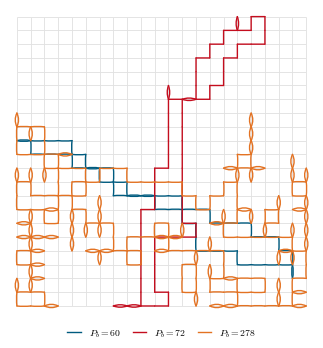

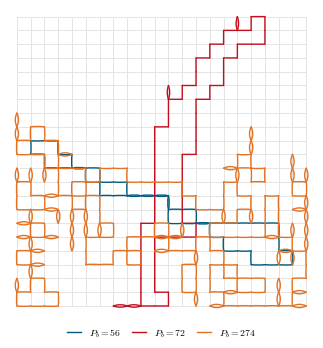

500 buses: P_b [50, 64, 148] -> [48, 64, 148]


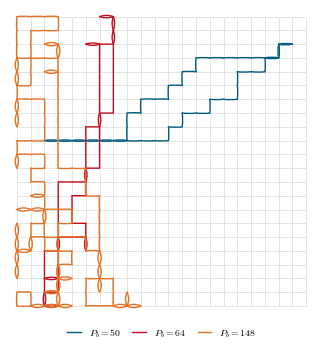

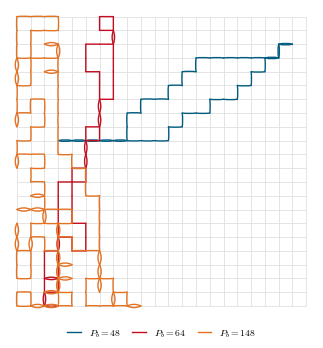

In [9]:
for B, run in runs.items():
    initial_examples, examples = examples_of(run)
    print(f"{B} buses: P_b {[bus.P_b for bus in initial_examples]} -> {[bus.P_b for bus in examples]}")
    route_figure(network, initial_examples, filename=f"{FIGURES}/example_routes_initial_N{B}.pdf")
    route_figure(network, examples, filename=f"{FIGURES}/example_routes_N{B}.pdf")

## Bus Lengths of the Whole Fleet

For the run of 500 buses.

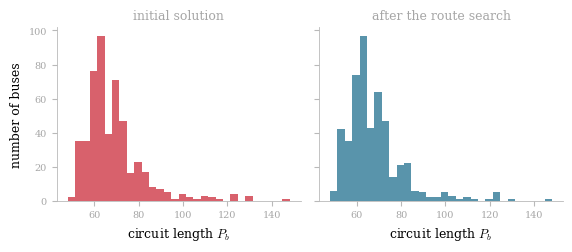

In [10]:
run = runs[DETAILED]
period_histogram({"initial solution": run["initial"], "after the route search": run["final"]},
                 filename=f"{FIGURES}/periods_N{DETAILED}.pdf");

## Load of the Underlying Undirected Network Edges

For the run of 500 buses.

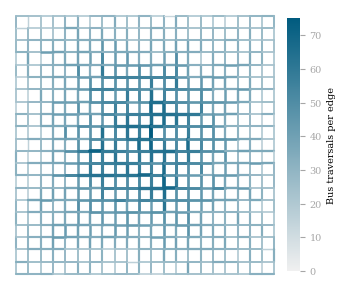

In [11]:
load_heatmap(network, run["final"], filename=f"{FIGURES}/load_N{DETAILED}.pdf");